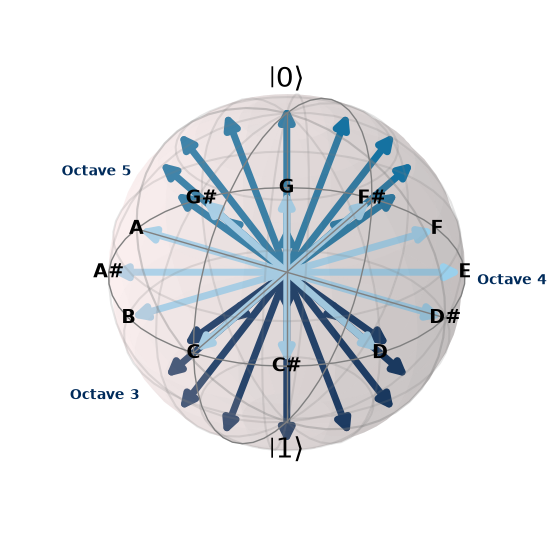

In [129]:
from qiskit.visualization import plot_bloch_vector
from qiskit.visualization.bloch import Bloch
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt
import numpy as np

# Helper function to map spherical (r, theta, phi) -> cartesian (x, y, z)
def spherical_to_cartesian(r, theta, phi):
    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)
    return [x, y, z]

# Set up a 3D Matplotlib axis
fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))

# Initialize Qiskit's Bloch class on that axis
b = Bloch(axes=ax)

# Arrays for notes and colour mapping.
notes = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
octave_colours = ["#1572A1", "#9AD0EC", "#002B5B"]
all_vector_colours = []

# Assign even spaced locations for each musical vector.
for j in [3, 1, 2]:
    octave = {}
    for i in range(0, 12):
        r = 1
        theta = j * np.pi / 4
        phi = (i / 6) * np.pi
        x, y, z = spherical_to_cartesian(r, theta, phi)
        
        octave[notes[i]] = [x, y, z]
        all_vector_colours.append(octave_colours[j-1])

    # Sequentially add vectors and text annotations
    for label, coords in octave.items():
        if j == 2:
            b.add_annotation(coords, label) # Annotations for middle octave.
            b.add_vectors(coords)
        else:
            b.add_vectors(coords)

# Render the multi-vector sphere
b.vector_color = all_vector_colors
b.render()

limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)

# Add octave labels.
b.axes.text(-1.4, 0.2, 0.15, "Octave 5", color="#002B5B", ha="center", weight="bold", fontsize=10, zorder=1000)
b.axes.text(1.3, 0.2, 0.2, "Octave 4", color="#002B5B", ha="center", weight="bold", fontsize=10, zorder=1000)
b.axes.text(-1.4, 0.2, -1.4, "Octave 3", color="#002B5B", ha="center", weight="bold", fontsize=10, zorder=1000)

base_labels = ['x', 'y', 'z']

# Loop through existing text annotations and set characteristics.
for text_obj in b.axes.texts:
    text_str = text_obj.get_text()
    if text_str in notes: 
        text_obj.set_fontsize(14)
        text_obj.set_weight('bold')
        zorder=1000
    
    if any(base_tag in text_str for base_tag in base_labels):
        text_obj.set_visible(False)

plt.show()


In [145]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  

# Initialize a clean 3D canvas
fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)

# Assign even spaced locations for each musical vector.
for j in [3, 1, 2]:
    octave = {}
    for i in range(0, 12):
        r = 1
        theta = j * np.pi / 4
        phi = (i / 6) * np.pi
        x, y, z = spherical_to_cartesian(r, theta, phi)
            
        octave[notes[i]] = [x, y, z]
        all_vector_colours.append(octave_colours[j-1])
    
    # Sequentially add vectors and text annotations
    for label, coords in octave.items():
        if j == 2:
            b.add_annotation(coords, label) # Annotations for middle octave.
            b.add_vectors(coords)
        else:
            b.add_vectors(coords)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = list(all_vector_colors)

# Setup padding boundaries
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)

# Frame configurations
frames_count = 30  # Sliced frame count slightly so it compiles instantly
theta_steps = np.linspace(0, 2 * np.pi, frames_count)

def update(frame):
    b.vectors = []  # Clear previous frame vector paths cleanly
    # Calculate state path rotation around X-axis
    
    theta = theta_steps[frame]
    x = 0
    y = np.sin(theta)
    z = np.cos(theta)
    moving_vector = [x, y, z]
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    b.vector_color = ["#1572A1"]
    b.vector_width = 4.0
    
    gate_color = ["#FF5733"]  # High-contrast orange/red for the moving gate vector
    b.vector_color = background_colors + gate_color
    
    # Use different line widths to separate the layers
    b.vector_width = 1.5  # Base width for background elements
    
    # Render the combined canvas scene
    b.render()
    b.render()
    
    # Hide default text elements
    for text_obj in b.axes.texts:
        if text_obj.get_text() in ['x', 'y', 'z']:
            text_obj.set_visible(False)
            
    return b.axes.artists

# 2. Build the animation tracking pipeline
ani = FuncAnimation(fig, update, frames=frames_count, interval=60, blit=False)
  # Closes the default layout window to avoid a frozen artifact print

# 3. SAVE AS A LOCAL GIF FILE
# This uses Matplotlib's native image writer (Pillow) which requires NO external system codecs
gif_path = "bloch_animation.gif"
ani.save(gif_path, writer='pillow', fps=15)

# 4. DISPLAY THE COPIED GIF DIRECTLY IN JUPYTER
# This requires zero JavaScript execution engines to play!
# display(Image(filename=gif_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

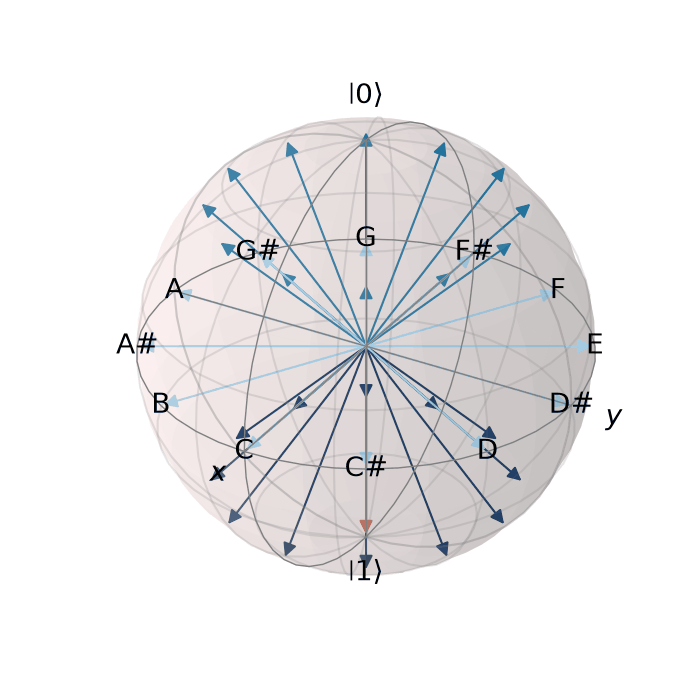

In [160]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from qiskit.visualization.bloch import Bloch
from IPython.display import Image, display  

# Initialize a clean 3D canvas
fig, ax = plt.subplots(subplot_kw=dict(projection="3d", computed_zorder=False), figsize=(7, 7))
b = Bloch(axes=ax)

# Assign even spaced locations for each musical vector.
for j in [3, 1, 2]:
    octave = {}
    for i in range(0, 12):
        r = 1
        theta = j * np.pi / 4
        phi = (i / 6) * np.pi
        x, y, z = spherical_to_cartesian(r, theta, phi)
            
        octave[notes[i]] = [x, y, z]
        all_vector_colours.append(octave_colours[j-1])
    
    # Sequentially add vectors and text annotations
    for label, coords in octave.items():
        if j == 2:
            b.add_annotation(coords, label) # Annotations for middle octave.
            b.add_vectors(coords)
        else:
            b.add_vectors(coords)

background_note_vectors = list(b.fixed_vectors) if hasattr(b, 'fixed_vectors') and b.fixed_vectors else list(b.vectors)
background_colors = list(all_vector_colors)

# Setup padding boundaries
limit = 0.9
ax.set_xlim3d(-limit, limit)
ax.set_ylim3d(-limit, limit)
ax.set_zlim3d(-limit, limit)

# Setup a circuit and get its statevector
qc = QuantumCircuit(1)
states = []
for i in range(30):
    qc.x(0)
    state = Statevector(qc)

    # Extract the complex amplitudes (alpha and beta)
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    states.append([x, y, z])

# Frame configurations
frames_count = 30  # Sliced frame count slightly so it compiles instantly

def update(frame):
    b.vectors = []  # Clear previous frame vector paths cleanly
    
    moving_vector = states[frame]
    b.vectors = list(background_note_vectors)
    b.add_vectors(moving_vector)
    
    b.vector_color = ["#1572A1"]
    b.vector_width = 4.0
    
    gate_color = ["#FF5733"]  # High-contrast orange/red for the moving gate vector
    b.vector_color = background_colors + gate_color
    
    # Use different line widths to separate the layers
    b.vector_width = 1.5  # Base width for background elements
    
    # Render the combined canvas scene
    b.render()
    b.render()
    
    # Hide default text elements
    for text_obj in b.axes.texts:
        if text_obj.get_text() in ['x', 'y', 'z']:
            text_obj.set_visible(False)
            
    return b.axes.artists

# 2. Build the animation tracking pipeline
ani = FuncAnimation(fig, update, frames=frames_count, interval=200, blit=False)
  # Closes the default layout window to avoid a frozen artifact print

# 3. SAVE AS A LOCAL GIF FILE
# This uses Matplotlib's native image writer (Pillow) which requires NO external system codecs
gif_path = "bloch_animation.gif"
ani.save(gif_path, writer='pillow', fps=15)

# 4. DISPLAY THE COPIED GIF DIRECTLY IN JUPYTER
# This requires zero JavaScript execution engines to play!
display(Image(filename=gif_path))


In [157]:

# Setup a circuit and get its statevector
qc = QuantumCircuit(1)
states = []
for i in range(30):
    qc.x(0)
    state = Statevector(qc)

    # Extract the complex amplitudes (alpha and beta)
    alpha = state.data[0]
    beta = state.data[1]

    # Compute Cartesian (x, y, z) coordinates 
    x = 2 * np.real(np.conj(alpha) * beta)
    y = 2 * np.imag(np.conj(alpha) * beta)
    z = np.abs(alpha)**2 - np.abs(beta)**2

    states.append([x, y, z])



[[np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), np.float64(-1.0)], [np.float64(0.0), np.float64(0.0), np.float64(1.0)], [np.float64(0.0), np.float64(0.0), n